# Medellin Edge-Slope Superlevel Filtration (Percentiles, 10 Steps)

This notebook computes persistent homology for **Medellin** using a **superlevel** edge-slope filtration.

Each edge slope is computed as `abs(elevation_u - elevation_v) / length_m` (always non-negative), and step `k` includes edges with **slope >= threshold_k**.

Thresholds are taken from **slope percentiles** (from the steepest decile down to the minimum).


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import osmnx as ox
from pathlib import Path

def find_repo_root(start=Path.cwd()) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "elevation_filtration_ph").exists():
            return candidate
    raise FileNotFoundError(f"Could not find urban_form repository from {start.resolve()}")

REPO_ROOT = find_repo_root()
ELEVATION_ROOT = REPO_ROOT / "elevation_filtration_ph"
FIGURES_DIR = ELEVATION_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

%matplotlib inline
warnings.filterwarnings("ignore", category=UserWarning)

In [2]:
graph_path = ELEVATION_ROOT / "data" / "manizales_rural_urbano.graphml"
if not graph_path.exists():
    raise FileNotFoundError(f"Graph file not found: {graph_path.resolve()}")

G = ox.load_graphml(graph_path)
print(f"Loaded graph: {graph_path}")
print(f"Nodes: {G.number_of_nodes():,} | Edges: {G.number_of_edges():,}")

Loaded graph: data/manizales_rural_urbano.graphml
Nodes: 5,352 | Edges: 13,038


In [3]:
def _to_float(value):
    if value is None:
        return np.nan
    try:
        return float(value)
    except (TypeError, ValueError):
        return np.nan

# Node elevation lookup
node_elev = {
    n: _to_float(data.get("elevation_m", data.get("elevation")))
    for n, data in G.nodes(data=True)
}

valid_nodes = [n for n, e in node_elev.items() if np.isfinite(e)]
if not valid_nodes:
    raise ValueError("No valid elevation attribute found on graph nodes.")

for n in valid_nodes:
    G.nodes[n]["elevation_m"] = float(node_elev[n])

valid_elev = np.array([node_elev[n] for n in valid_nodes], dtype=float)
missing = G.number_of_nodes() - len(valid_nodes)

# Edge slope lookup: abs(delta elevation)/length (m/m), always non-negative
edge_slope = {}
for u, v, k, data in G.edges(keys=True, data=True):
    eu = node_elev.get(u, np.nan)
    ev = node_elev.get(v, np.nan)
    length_m = _to_float(data.get("length"))

    if not (np.isfinite(eu) and np.isfinite(ev)):
        continue
    if not (np.isfinite(length_m) and length_m > 0):
        continue

    slope = abs(ev - eu) / length_m
    if np.isfinite(slope):
        edge_slope[(u, v, k)] = float(slope)

if not edge_slope:
    raise ValueError("No valid edge slope could be computed. Check elevation and edge length attributes.")

slope_values = np.array(list(edge_slope.values()), dtype=float)

print(f"Nodes with valid elevation: {len(valid_nodes):,}")
print(f"Nodes missing elevation: {missing:,}")
print(f"Elevation range (m): {valid_elev.min():.2f} to {valid_elev.max():.2f}")
print(f"Edges with valid slope: {len(edge_slope):,}")
print(f"Slope range (m/m): {slope_values.min():.6f} to {slope_values.max():.6f}")

Nodes with valid elevation: 5,352
Nodes missing elevation: 0
Elevation range (m): 1850.00 to 2436.00
Edges with valid slope: 13,038
Slope range (m/m): 0.000000 to 0.581562


In [4]:
def build_slope_superlevel_filtration_percentile(G, edge_slope, n_steps=10):
    # Build superlevel filtration with percentile thresholds.
    if n_steps <= 0:
        raise ValueError("n_steps must be > 0")
    if not edge_slope:
        raise ValueError("edge_slope is empty")

    slope_values = np.array(list(edge_slope.values()), dtype=float)

    percentiles = np.linspace(0.90, 0.00, n_steps)
    thresholds = np.quantile(slope_values, percentiles)

    filtration = []
    for step, (thr, p) in enumerate(zip(thresholds, percentiles), start=1):
        edges_step = [edge for edge, slope in edge_slope.items() if slope >= thr]
        H = G.edge_subgraph(edges_step).copy()

        U = nx.Graph(H.to_undirected())
        U.remove_edges_from(nx.selfloop_edges(U))

        n_nodes = U.number_of_nodes()
        n_edges = U.number_of_edges()
        beta0 = nx.number_connected_components(U) if n_nodes > 0 else 0
        beta1 = n_edges - n_nodes + beta0 if n_nodes > 0 else 0

        filtration.append({
            "step": step,
            "percentile": float(p),
            "threshold_slope": float(thr),
            "graph": H,
            "edges": set(edges_step),
            "n_nodes": int(H.number_of_nodes()),
            "n_edges": int(H.number_of_edges()),
            "beta0": int(beta0),
            "beta1": int(beta1),
        })

    return filtration

filtration = build_slope_superlevel_filtration_percentile(G, edge_slope=edge_slope, n_steps=10)

summary_df = pd.DataFrame([
    {
        "step": f["step"],
        "percentile": f["percentile"],
        "threshold_slope": f["threshold_slope"],
        "nodes": f["n_nodes"],
        "edges": f["n_edges"],
        "beta0": f["beta0"],
        "beta1": f["beta1"],
    }
    for f in filtration
])

summary_df


,step,percentile,threshold_slope,nodes,edges,beta0,beta1
0,1,0.9,0.217388,1259,1304,535,3
1,2,0.8,0.168743,2306,2609,858,14
2,3,0.7,0.135615,3138,3913,955,39
3,4,0.6,0.109689,3794,5216,897,97
4,5,0.5,0.087552,4330,6519,764,209
5,6,0.4,0.069020,4728,7823,570,400
6,7,0.3,0.049785,5002,9126,308,665
7,8,0.2,0.031656,5187,10430,122,1091
8,9,0.1,0.011850,5293,11734,27,1689
9,10,0.0,0.000000,5352,13038,1,2408


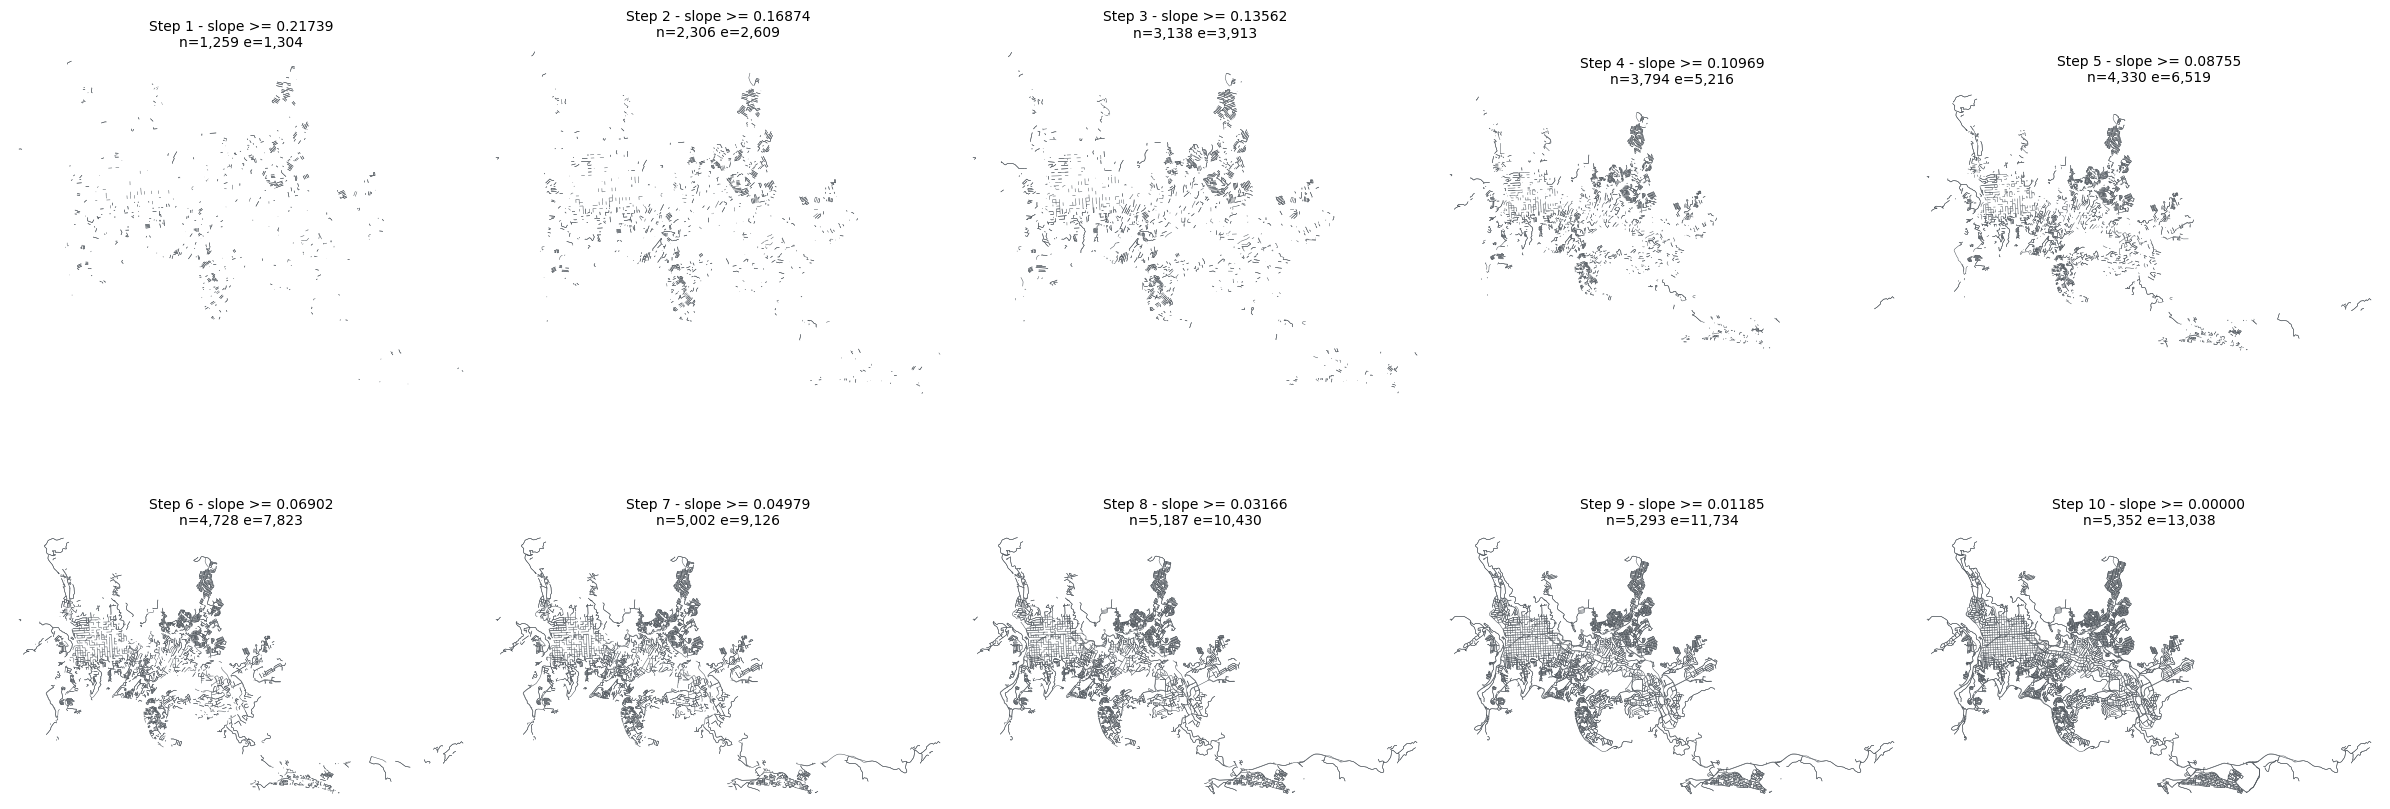

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(24, 10))
axes = axes.ravel()

for ax, item in zip(axes, filtration):
    H = item["graph"]
    title = (
        f"Step {item['step']} - slope >= {item['threshold_slope']:.5f}\n"
        f"n={item['n_nodes']:,} e={item['n_edges']:,}"
    )

    if H.number_of_nodes() == 0:
        ax.set_title(title)
        ax.axis("off")
        continue

    ox.plot_graph(
        H,
        ax=ax,
        show=False,
        close=False,
        node_size=0,
        edge_linewidth=0.35,
        node_color="#0b7285",
        edge_color="#495057",
        bgcolor="white",
    )
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()

plt.tight_layout()
# plt.savefig(FIGURES_DIR / "manizales_slope_superlevel_filtration_percentiles.png", dpi=300, bbox_inches="tight")
plt.show()


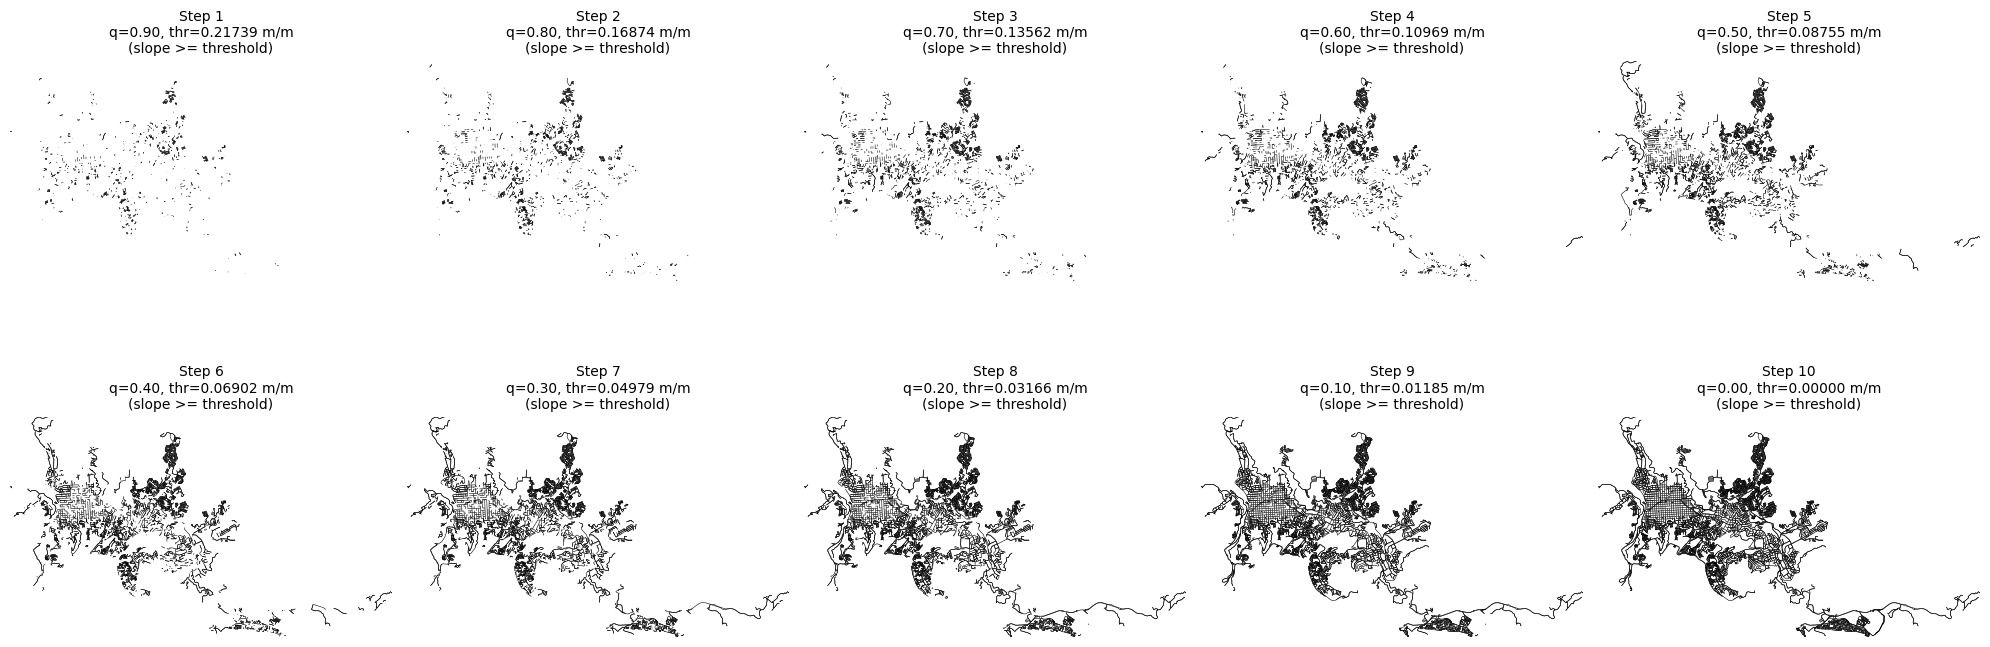


Final graph summary
Nodes: 5352
Edges: 7759

Simplex tree summary
Dimension: 1
Num vertices: 5352
Num simplices: 13111

Finite H1 intervals:
[]

Graph-theoretic diagnostics
Connected components: 1
Cycle rank: 2408

Betti numbers:
[1, 2408]


<Figure size 700x600 with 0 Axes>

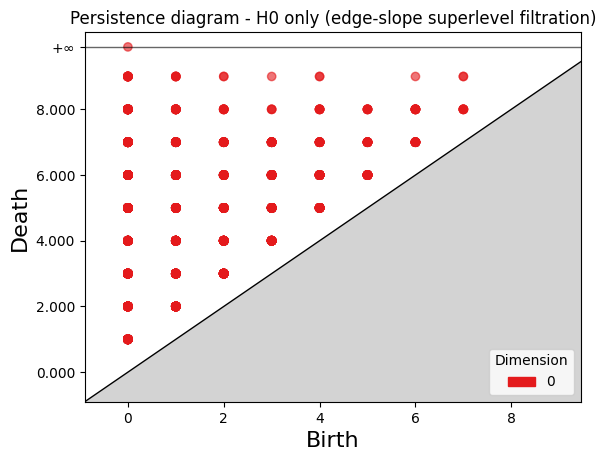

<Figure size 1000x400 with 0 Axes>

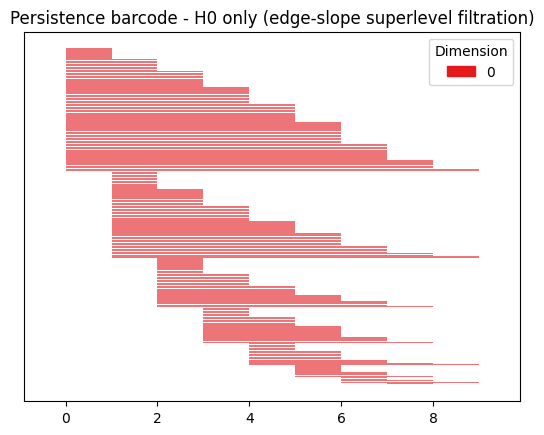

<Figure size 700x600 with 0 Axes>

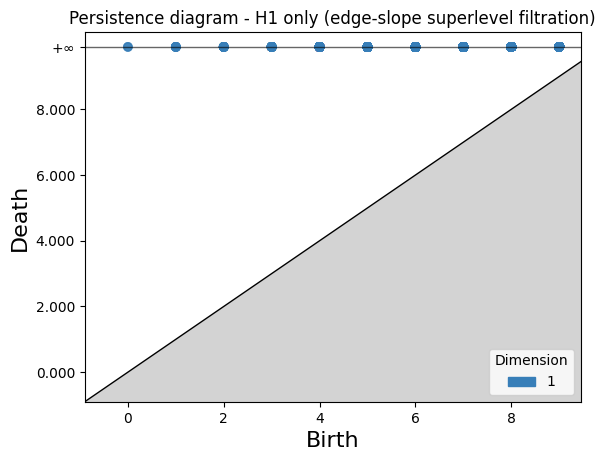

<Figure size 1000x400 with 0 Axes>

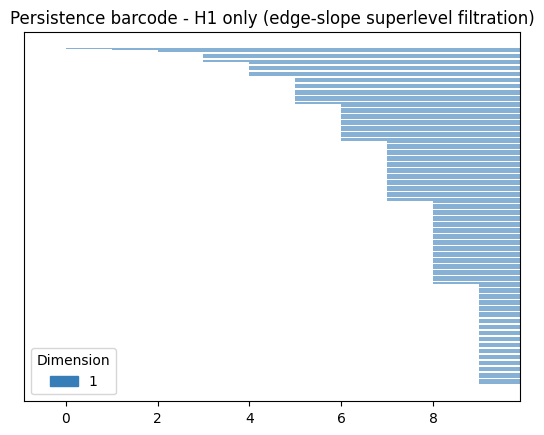


Step-by-step filtration summary

Step 1 -> q=0.90, threshold=0.21739 m/m (slope >= threshold)
Nodes: 1259
Edges: 727
Connected components: 535
Cycle rank: 3

Step 2 -> q=0.80, threshold=0.16874 m/m (slope >= threshold)
Nodes: 2306
Edges: 1462
Connected components: 858
Cycle rank: 14

Step 3 -> q=0.70, threshold=0.13562 m/m (slope >= threshold)
Nodes: 3138
Edges: 2222
Connected components: 955
Cycle rank: 39

Step 4 -> q=0.60, threshold=0.10969 m/m (slope >= threshold)
Nodes: 3794
Edges: 2994
Connected components: 897
Cycle rank: 97

Step 5 -> q=0.50, threshold=0.08755 m/m (slope >= threshold)
Nodes: 4330
Edges: 3775
Connected components: 764
Cycle rank: 209

Step 6 -> q=0.40, threshold=0.06902 m/m (slope >= threshold)
Nodes: 4728
Edges: 4558
Connected components: 570
Cycle rank: 400

Step 7 -> q=0.30, threshold=0.04979 m/m (slope >= threshold)
Nodes: 5002
Edges: 5359
Connected components: 308
Cycle rank: 665

Step 8 -> q=0.20, threshold=0.03166 m/m (slope >= threshold)
Nodes: 5187
Edg

In [6]:
# If needed once:
# !pip install gudhi

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import osmnx as ox
import gudhi

ox.settings.use_cache = True
ox.settings.log_console = True

n_steps = 10

def to_float(x):
    try:
        val = float(x)
        return val if np.isfinite(val) else np.nan
    except (TypeError, ValueError):
        return np.nan

def build_slope_superlevel_filtration_percentile(G, edge_slope, n_steps=10):
    # Build superlevel filtration with percentile thresholds.
    if n_steps <= 0:
        raise ValueError("n_steps must be > 0")
    if not edge_slope:
        raise ValueError("edge_slope is empty")

    slope_values = np.array(list(edge_slope.values()), dtype=float)
    percentiles = np.linspace(0.90, 0.00, n_steps)
    thresholds = np.quantile(slope_values, percentiles)

    filtration = []
    for step, (thr, p) in enumerate(zip(thresholds, percentiles), start=1):
        edges_step = [edge for edge, slope in edge_slope.items() if slope >= thr]
        H = G.edge_subgraph(edges_step).copy()

        U = nx.Graph(H.to_undirected())
        U.remove_edges_from(nx.selfloop_edges(U))

        n_nodes = U.number_of_nodes()
        n_edges = U.number_of_edges()
        beta0 = nx.number_connected_components(U) if n_nodes > 0 else 0
        beta1 = n_edges - n_nodes + beta0 if n_nodes > 0 else 0

        filtration.append({
            "step": step,
            "percentile": float(p),
            "threshold_slope": float(thr),
            "graph": H,
            "edges": set(edges_step),
            "n_nodes": int(n_nodes),
            "n_edges": int(n_edges),
            "beta0": int(beta0),
            "beta1": int(beta1),
        })

    return filtration

# Node elevations
node_elev = {}
for n, data in G.nodes(data=True):
    e = data.get("elevation_m", data.get("elevation"))
    e = to_float(e)
    if np.isfinite(e):
        node_elev[n] = e

if len(node_elev) == 0:
    raise ValueError("No valid elevation attribute found (expected 'elevation_m' or 'elevation').")

# Edge slopes (always positive)
edge_slope = {}
for u, v, k, data in G.edges(keys=True, data=True):
    eu = node_elev.get(u, np.nan)
    ev = node_elev.get(v, np.nan)
    length_m = to_float(data.get("length"))

    if not (np.isfinite(eu) and np.isfinite(ev)):
        continue
    if not (np.isfinite(length_m) and length_m > 0):
        continue

    slope = abs(ev - eu) / length_m
    if np.isfinite(slope):
        edge_slope[(u, v, k)] = float(slope)

if len(edge_slope) == 0:
    raise ValueError("No valid edge slope computed.")

# Build superlevel filtration using percentile thresholds
filtration = build_slope_superlevel_filtration_percentile(G, edge_slope=edge_slope, n_steps=n_steps)
thresholds = np.array([f["threshold_slope"] for f in filtration], dtype=float)
percentiles = np.array([f["percentile"] for f in filtration], dtype=float)

# Edge filtration time: first step where edge appears (0..n_steps-1)
# thresholds are descending, so we use searchsorted on the negated array.
edge_filtration = {}
for edge_key, s in edge_slope.items():
    t = int(np.searchsorted(-thresholds, -s, side="left"))
    t = min(t, n_steps - 1)
    edge_filtration[edge_key] = t

# Node filtration time: first incident edge appearance
node_filtration = {}
for (u, v, _k), t in edge_filtration.items():
    if u in node_filtration:
        node_filtration[u] = min(node_filtration[u], t)
    else:
        node_filtration[u] = t

    if v in node_filtration:
        node_filtration[v] = min(node_filtration[v], t)
    else:
        node_filtration[v] = t

# Prepare edge GeoDataFrame for snapshots
edges = ox.graph_to_gdfs(G, nodes=False).copy()
u_idx = edges.index.get_level_values(0)
v_idx = edges.index.get_level_values(1)
k_idx = edges.index.get_level_values(2)

mask = [(u, v, k) in edge_filtration for u, v, k in zip(u_idx, v_idx, k_idx)]
edges = edges[mask].copy()

u_idx = edges.index.get_level_values(0)
v_idx = edges.index.get_level_values(1)
k_idx = edges.index.get_level_values(2)

edges["slope"] = [edge_slope[(u, v, k)] for u, v, k in zip(u_idx, v_idx, k_idx)]
edges["filtration"] = [edge_filtration[(u, v, k)] for u, v, k in zip(u_idx, v_idx, k_idx)]

xmin, ymin, xmax, ymax = edges.total_bounds

# Plot filtration snapshots
cols = 5
rows = int(np.ceil(n_steps / cols))

fig, axes = plt.subplots(rows, cols, figsize=(20, 4 * rows))
axes = np.array(axes).flatten()

for t in range(n_steps):
    ax = axes[t]
    subset = edges[edges["filtration"] <= t]

    if not subset.empty:
        subset.plot(ax=ax, linewidth=0.4, color="black")

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(
        f"Step {t+1}\nq={percentiles[t]:.2f}, thr={thresholds[t]:.5f} m/m\n(slope >= threshold)",
        fontsize=10
    )
    ax.set_axis_off()

for j in range(n_steps, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

# Build simple undirected graph for PH (1-skeleton)
H = nx.Graph()

for n, t in node_filtration.items():
    H.add_node(n, filtration=t)

for (u, v, _k), t in edge_filtration.items():
    if u == v:
        continue
    if (u not in node_filtration) or (v not in node_filtration):
        continue

    if H.has_edge(u, v):
        H[u][v]["filtration"] = min(H[u][v]["filtration"], t)
    else:
        H.add_edge(u, v, filtration=t)

print("\nFinal graph summary")
print("Nodes:", H.number_of_nodes())
print("Edges:", H.number_of_edges())

# Build Gudhi simplex tree
st = gudhi.SimplexTree()

node_to_int = {node: i for i, node in enumerate(H.nodes())}

for node, data in H.nodes(data=True):
    st.insert([node_to_int[node]], filtration=float(data["filtration"]))

for u, v, data in H.edges(data=True):
    st.insert([node_to_int[u], node_to_int[v]], filtration=float(data["filtration"]))

st.make_filtration_non_decreasing()

print("\nSimplex tree summary")
print("Dimension:", st.dimension())
print("Num vertices:", st.num_vertices())
print("Num simplices:", st.num_simplices())

# Compute persistence
diag = st.persistence(
    homology_coeff_field=2,
    persistence_dim_max=True
)

h0 = st.persistence_intervals_in_dimension(0)
h1 = st.persistence_intervals_in_dimension(1)

h1_finite = h1[np.isfinite(h1).all(axis=1)] if len(h1) > 0 else np.empty((0, 2))
print("\nFinite H1 intervals:")
print(h1_finite)

if len(h1_finite) > 0:
    h1_lengths = h1_finite[:, 1] - h1_finite[:, 0]
    print("\nFinite H1 bar lengths:")
    print(h1_lengths)

# Graph-theoretic check
c = nx.number_connected_components(H)
m = H.number_of_edges()
n_nodes = H.number_of_nodes()
cycle_rank = m - n_nodes + c

print("\nGraph-theoretic diagnostics")
print("Connected components:", c)
print("Cycle rank:", cycle_rank)

# Betti numbers
bettis = st.betti_numbers()
print("\nBetti numbers:")
print(bettis)

# Plot H0 only
if len(h0) > 0:
    h0_diag = [(0, (birth, death)) for birth, death in h0]

    plt.figure(figsize=(7, 6))
    gudhi.plot_persistence_diagram(h0_diag)
    plt.title("Persistence diagram - H0 only (edge-slope superlevel filtration)")
    plt.show()

    plt.figure(figsize=(10, 4))
    gudhi.plot_persistence_barcode(h0_diag)
    plt.title("Persistence barcode - H0 only (edge-slope superlevel filtration)")
    plt.show()
else:
    print("\nNo H0 intervals found.")

# Plot H1 only
if len(h1) > 0:
    h1_diag = [(1, (birth, death)) for birth, death in h1]

    plt.figure(figsize=(7, 6))
    gudhi.plot_persistence_diagram(h1_diag)
    plt.title("Persistence diagram - H1 only (edge-slope superlevel filtration)")
    plt.show()

    plt.figure(figsize=(10, 4))
    gudhi.plot_persistence_barcode(h1_diag)
    plt.title("Persistence barcode - H1 only (edge-slope superlevel filtration)")
    plt.show()
else:
    print("\nNo H1 intervals found.")

# Step-by-step filtration check
print("\nStep-by-step filtration summary")
for t in range(n_steps):
    nodes_t = [n for n, d in H.nodes(data=True) if d["filtration"] <= t]
    edges_t = [(u, v) for u, v, d in H.edges(data=True) if d["filtration"] <= t]

    G_t = nx.Graph()
    G_t.add_nodes_from(nodes_t)
    G_t.add_edges_from(edges_t)

    n_t = G_t.number_of_nodes()
    m_t = G_t.number_of_edges()
    c_t = nx.number_connected_components(G_t) if n_t > 0 else 0
    cycle_rank_t = m_t - n_t + c_t if n_t > 0 else 0

    print(f"\nStep {t+1} -> q={percentiles[t]:.2f}, threshold={thresholds[t]:.5f} m/m (slope >= threshold)")
    print("Nodes:", n_t)
    print("Edges:", m_t)
    print("Connected components:", c_t)
    print("Cycle rank:", cycle_rank_t)


In [7]:
rows = []

for f in filtration:
    H = f["graph"]

    U = nx.Graph(H.to_undirected())
    U.remove_edges_from(nx.selfloop_edges(U))

    n = U.number_of_nodes()
    m = U.number_of_edges()
    c = nx.number_connected_components(U) if n > 0 else 0

    beta1 = (m - n + c) if n > 0 else 0
    cycle_edge_ratio = (beta1 / m) if m > 0 else np.nan

    rows.append({
        "step": f["step"],
        "threshold_slope": f["threshold_slope"],
        "nodes": n,
        "edges": m,
        "beta1_cycles": beta1,
        "cycle_edge_ratio": cycle_edge_ratio,
    })

cycle_edge_df = pd.DataFrame(rows)
cycle_edge_df

,step,threshold_slope,nodes,edges,beta1_cycles,cycle_edge_ratio
0,1,0.217388,1259,727,3,0.004127
1,2,0.168743,2306,1462,14,0.009576
2,3,0.135615,3138,2222,39,0.017552
3,4,0.109689,3794,2994,97,0.032398
4,5,0.087552,4330,3775,209,0.055364
5,6,0.069020,4728,4558,400,0.087758
6,7,0.049785,5002,5359,665,0.124090
7,8,0.031656,5187,6156,1091,0.177225
8,9,0.011850,5293,6955,1689,0.242847
9,10,0.000000,5352,7759,2408,0.310349


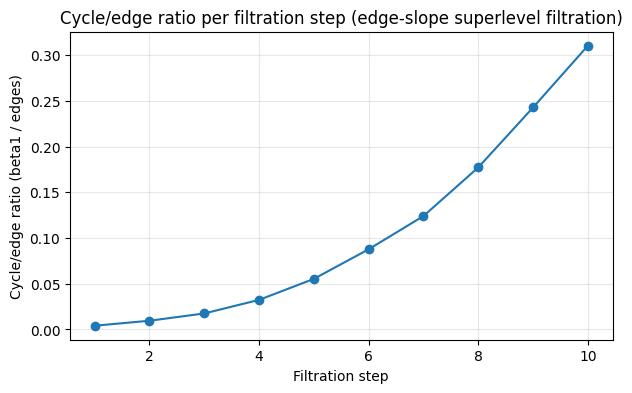

In [8]:
plt.figure(figsize=(7, 4))
plt.plot(cycle_edge_df["step"], cycle_edge_df["cycle_edge_ratio"], marker="o")
plt.xlabel("Filtration step")
plt.ylabel("Cycle/edge ratio (beta1 / edges)")
plt.title("Cycle/edge ratio per filtration step (edge-slope superlevel filtration)")
plt.grid(alpha=0.3)
plt.show()


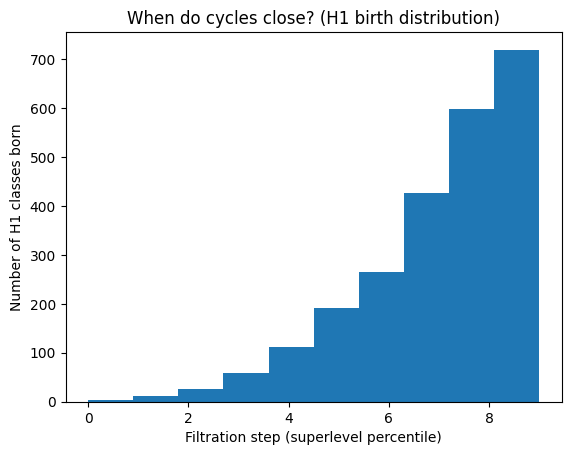

In [9]:
if len(h1) > 0:
    h1_births = h1[:, 0]
    plt.hist(h1_births, bins=n_steps)
    plt.xlabel("Filtration step (superlevel percentile)")
    plt.ylabel("Number of H1 classes born")
    plt.title("When do cycles close? (H1 birth distribution)")
    plt.show()
else:
    print("No H1 intervals available for birth histogram.")


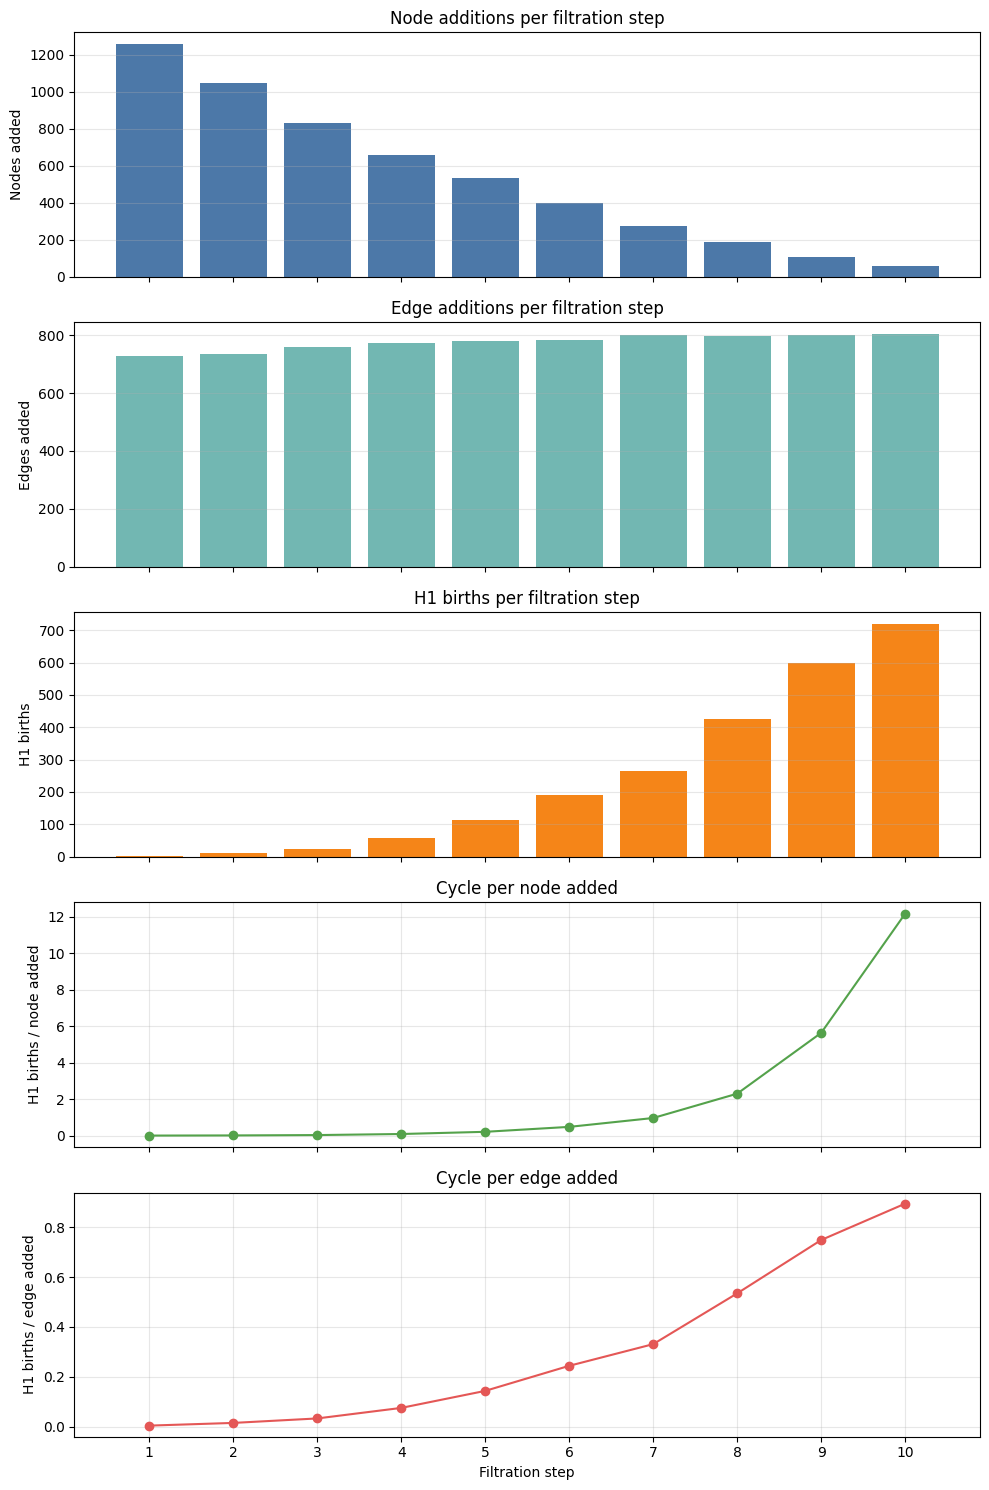

In [10]:
node_additions = [
    filtration[t]["n_nodes"] - (filtration[t - 1]["n_nodes"] if t > 0 else 0)
    for t in range(n_steps)
]

edge_additions = [
    filtration[t]["n_edges"] - (filtration[t - 1]["n_edges"] if t > 0 else 0)
    for t in range(n_steps)
]

if len(h1) > 0:
    h1_births_per_step = [sum(1 for b, _ in h1 if int(b) == t) for t in range(n_steps)]
else:
    h1_births_per_step = [0] * n_steps

cycle_per_node_added = [
    h / n if n > 0 else 0
    for h, n in zip(h1_births_per_step, node_additions)
]

cycle_per_edge_added = [
    h / e if e > 0 else 0
    for h, e in zip(h1_births_per_step, edge_additions)
]

steps = np.arange(1, n_steps + 1)

fig, axes = plt.subplots(5, 1, figsize=(10, 15), sharex=True)

axes[0].bar(steps, node_additions, color="#4c78a8")
axes[0].set_ylabel("Nodes added")
axes[0].set_title("Node additions per filtration step")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(steps, edge_additions, color="#72b7b2")
axes[1].set_ylabel("Edges added")
axes[1].set_title("Edge additions per filtration step")
axes[1].grid(axis="y", alpha=0.3)

axes[2].bar(steps, h1_births_per_step, color="#f58518")
axes[2].set_ylabel("H1 births")
axes[2].set_title("H1 births per filtration step")
axes[2].grid(axis="y", alpha=0.3)

axes[3].plot(steps, cycle_per_node_added, marker="o", color="#54a24b")
axes[3].set_ylabel("H1 births / node added")
axes[3].set_title("Cycle per node added")
axes[3].grid(alpha=0.3)

axes[4].plot(steps, cycle_per_edge_added, marker="o", color="#e45756")
axes[4].set_ylabel("H1 births / edge added")
axes[4].set_xlabel("Filtration step")
axes[4].set_title("Cycle per edge added")
axes[4].grid(alpha=0.3)

for ax in axes:
    ax.set_xticks(steps)

plt.tight_layout()
# plt.savefig(FIGURES_DIR / 'mde_superlevel_results.png')
plt.show()
